# 10. Perceptron (averaged)

Rosenblatt's perceptron: for every misclassified borrower, `w <- w + lr * y * x`. The data is not linearly
separable, so the plain version never settles; the **averaged** perceptron reports the average of all
weight vectors seen during training, which is stable. Probabilities come from Platt scaling.

From-scratch code: `Notebooks/src/ClassificationAlgorithms/Perceptron.py` · charts + tables: `Results/Classification/10_Perceptron/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 60/20/20 train/validation/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "src", "Common")))

import numpy as np
import pandas as pd
from project import SEED, Outputs, classification_data, imbalance_weight
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from Perceptron import PerceptronScratch
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
import plots

out = Outputs("Classification", "10_Perceptron")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. Model

In [2]:
# Model: build the from-scratch model and train it (validation set = early stopping)
model = PerceptronScratch(variant="averaged", learning_rate=0.1, n_epochs=40, random_state=SEED)
check_settings("Perceptron (averaged)", model)
model.fit(d.X_tr, d.y_tr, eval_set=[(d.X_va, d.y_va)], feature_names=d.feature_cols, early_stopping_rounds=30)
p_te = model.predict_proba(d.X_te)[:, 1]

# verification: scikit-learn SGDClassifier(loss="perceptron", average=True) with the same weights
w_tr = imbalance_weight(d.y_tr)
sc = StandardScaler().fit(d.X_tr)
sk = SGDClassifier(
    loss="perceptron",
    penalty=None,
    learning_rate="constant",
    eta0=0.1,
    average=True,
    max_iter=40,
    tol=None,
    class_weight={0: 1, 1: float(w_tr.max())},
    random_state=SEED,
).fit(sc.transform(d.X_tr), d.y_tr)
check = sklearn_check(
    "Averaged perceptron vs SGDClassifier(perceptron, average)",
    np.nan,
    roc_auc(d.y_te, model.decision_function(d.X_te)),
    roc_auc(d.y_te, sk.decision_function(sc.transform(d.X_te))),
    "AUC only",
)

settings match Common/model_zoo.py (6 values checked)


## 3. Results

                                  test set  at plain 0.5
threshold (chosen on validation)    0.2402        0.5000
log loss                            0.4626           NaN
accuracy                            0.4541        0.8262
precision                           0.2076        0.3772
recall / sensitivity                0.8623        0.1410
specificity                         0.3768           NaN
F1                                  0.3346        0.2053
ROC-AUC                             0.6913           NaN
PR-AUC                              0.2931           NaN
defaulters missed (FN)             42.0000           NaN

catches 86.2% of the 305 test defaulters (42 missed), flags 66.1% of applicants


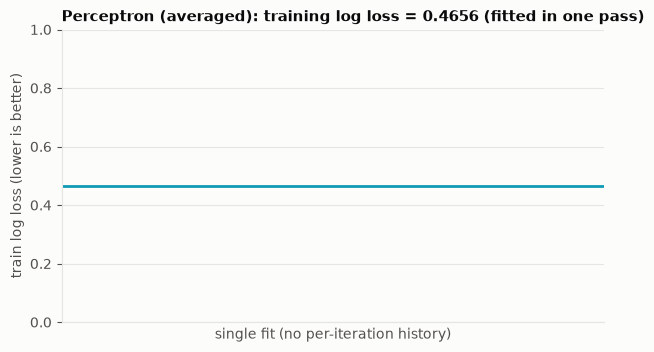

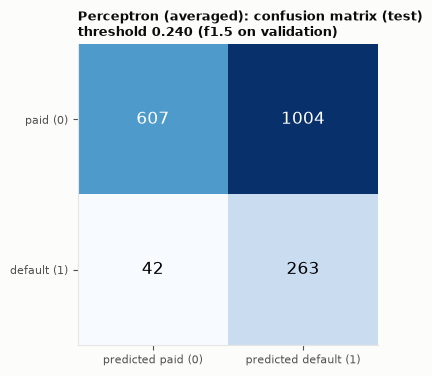

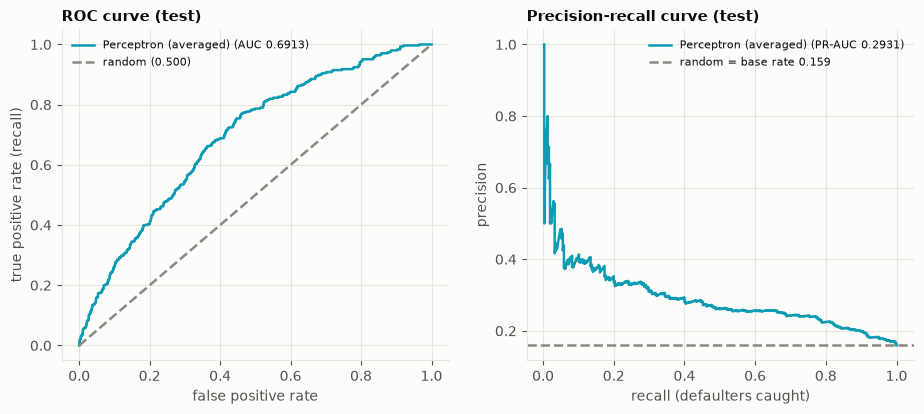

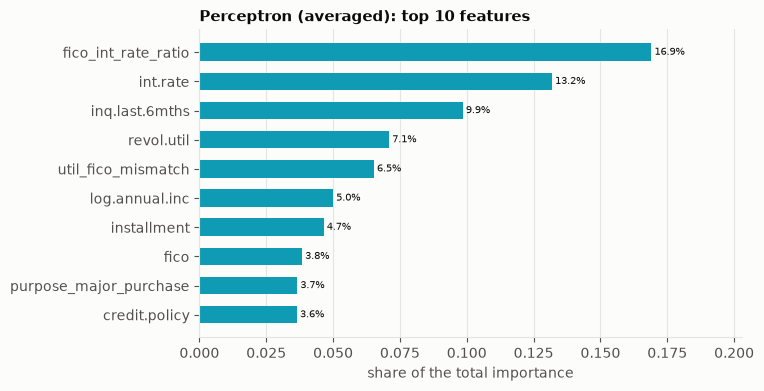


scratch vs library:
  Averaged perceptron vs SGDClassifier(perceptron, average)
    AUC scratch 0.6913 | AUC library 0.6924 | AUC only = nan

saved + reloaded Results/Classification/10_Perceptron/model.joblib (identical predictions: True)



          val ROC-AUC  test ROC-AUC  mistakes in last epoch  converged
variant                                                               
classic      0.416987      0.424290                    1998      False
pocket       0.635111      0.666791                    1998      False
averaged     0.663316      0.691274                    1998      False


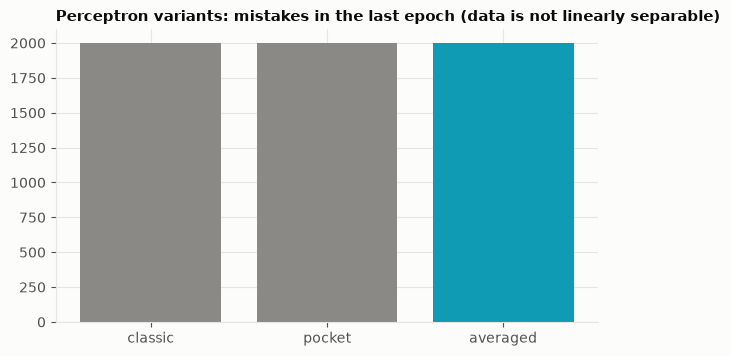

In [3]:
# Results: metrics at the validation-chosen threshold, charts, scratch-vs-library check, saved model
row = report_classifier(out, "Perceptron (averaged)", model, d, check)

# why "averaged": the three variants side by side (the data is not linearly separable)
rows = []
for v in ("classic", "pocket", "averaged"):
    pm = PerceptronScratch(variant=v, learning_rate=0.1, n_epochs=40, random_state=SEED).fit(
        d.X_tr, d.y_tr, eval_set=[(d.X_va, d.y_va)], feature_names=d.feature_cols
    )
    rows.append(
        {
            "variant": v,
            "val ROC-AUC": roc_auc(d.y_va, pm.decision_function(d.X_va)),
            "test ROC-AUC": roc_auc(d.y_te, pm.decision_function(d.X_te)),
            "mistakes in last epoch": pm.history_["mistakes"][-1],
            "converged": pm.converged_,
        }
    )
pv = pd.DataFrame(rows).set_index("variant")
pv.to_csv(out.table("perceptron_variants.csv"))
print("\n" + pv.to_string())
fig, ax = plots.plt.subplots(figsize=(7, 3.8))
ax.bar(
    pv.index, pv["mistakes in last epoch"], color=["#0f9bb3" if v == "averaged" else plots.NEUTRAL for v in pv.index]
)
ax.set_title("Perceptron variants: mistakes in the last epoch (data is not linearly separable)")
plots._save(fig, out.image("perceptron_variants.png"))